# Lab 9: K-Means Clustering

## Aim
Perform clustering on the **Airplane Crashes and Fatalities Since 1908** dataset using K-Means. Find a suitable number of clusters using the **Elbow Method** and **Silhouette Score**, then visualize and interpret the clusters.

## What this notebook does
1. Load and explore the dataset.
2. Prepare numerical features related to crash severity.
3. Scale the data so that all features are on a comparable scale.
4. Use the Elbow Method and Silhouette Score to compare different values of K.
5. Train the final K-Means model and visualize the clusters.

**Note:** K-Means is an unsupervised learning algorithm. It groups similar crash records; it does not predict a known target or prove why a crash happened. The clusters are exploratory patterns in this dataset.


## 1. Import the required libraries
We use pandas to work with the dataset, matplotlib to draw graphs, and scikit-learn for preprocessing and K-Means.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)


## 2. Load the dataset
Keep the CSV file in the same folder as this notebook.

In [2]:
file_name = "Airplane_Crashes_and_Fatalities_Since_1908.csv"
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (5268, 13)


,Date,Time,Location,Operator,Flight #,Route,Type,Registration,cn/In,Aboard,Fatalities,Ground,Summary
0,09/17/1908,17:18,"Fort Myer, Virginia",Military - U.S. Army,NaN,Demonstration,Wright Flyer III,NaN,1,2.0,1.0,0.0,"During a demonstration flight, a U.S. Army fly..."
1,07/12/1912,06:30,"AtlantiCity, New Jersey",Military - U.S. Navy,NaN,Test flight,Dirigible,NaN,NaN,5.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...
2,08/06/1913,NaN,"Victoria, British Columbia, Canada",Private,-,NaN,Curtiss seaplane,NaN,NaN,1.0,1.0,0.0,The first fatal airplane accident in Canada oc...
3,09/09/1913,18:30,Over the North Sea,Military - German Navy,NaN,NaN,Zeppelin L-1 (airship),NaN,NaN,20.0,14.0,0.0,The airship flew into a thunderstorm and encou...
4,10/17/1913,10:30,"Near Johannisthal, Germany",Military - German Navy,NaN,NaN,Zeppelin L-2 (airship),NaN,NaN,30.0,30.0,0.0,Hydrogen gas which was being vented was sucked...


## 3. Explore the data
Check the column names, data types, and missing values before selecting features.

In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in important columns:")
display(df[["Date", "Aboard", "Fatalities", "Ground"]].isnull().sum().to_frame("Missing values"))


Columns:
['Date', 'Time', 'Location', 'Operator', 'Flight #', 'Route', 'Type', 'Registration', 'cn/In', 'Aboard', 'Fatalities', 'Ground', 'Summary']

Data types:
Date                str
Time                str
Location            str
Operator            str
Flight #            str
Route               str
Type                str
Registration        str
cn/In               str
Aboard          float64
Fatalities      float64
Ground          float64
Summary             str
dtype: object

Missing values in important columns:


,Missing values
Date,0
Aboard,22
Fatalities,12
Ground,22


## 4. Prepare features for clustering

For this lab, we cluster crashes using four numerical features:

- **Aboard:** number of people aboard the aircraft.
- **Fatalities:** number of people who died in the crash.
- **Ground:** number of people on the ground who died.
- **Fatality_Rate:** fatalities divided by people aboard.

The date and text columns are not used by K-Means here. Count features are transformed with `log1p` to reduce the influence of very large values. Missing or invalid numeric values are replaced with the median. The fatality rate is limited to the range 0 to 1 for a simple proportion-based feature.


In [4]:
# Convert the count columns to numeric values.
feature_df = df[["Aboard", "Fatalities", "Ground"]].copy()
for column in feature_df.columns:
    feature_df[column] = pd.to_numeric(feature_df[column], errors="coerce")
    feature_df.loc[feature_df[column] < 0, column] = np.nan

# Calculate fatality rate. Rows with missing values are handled below.
feature_df["Fatality_Rate"] = feature_df["Fatalities"] / feature_df["Aboard"].replace(0, np.nan)
feature_df["Fatality_Rate"] = feature_df["Fatality_Rate"].clip(lower=0, upper=1)

# Replace missing values using the median of each feature.
feature_df = feature_df.replace([np.inf, -np.inf], np.nan)
feature_df = feature_df.fillna(feature_df.median())

print("Prepared feature shape:", feature_df.shape)
display(feature_df.head())
print("\nMissing values after cleaning:")
print(feature_df.isnull().sum())


Prepared feature shape: (5268, 4)


,Aboard,Fatalities,Ground,Fatality_Rate
0,2.0,1.0,0.0,0.5
1,5.0,5.0,0.0,1.0
2,1.0,1.0,0.0,1.0
3,20.0,14.0,0.0,0.7
4,30.0,30.0,0.0,1.0



Missing values after cleaning:
Aboard           0
Fatalities       0
Ground           0
Fatality_Rate    0
dtype: int64


## 5. Transform and scale the features
`log1p` is used on the three count columns. `StandardScaler` then gives each feature a similar scale, which is important because K-Means uses distance calculations.

In [5]:
X = feature_df.copy()

count_columns = ["Aboard", "Fatalities", "Ground"]
X[count_columns] = np.log1p(X[count_columns])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)


Scaled data shape: (5268, 4)


## 6. Find a suitable number of clusters

We test K values from 2 to 10.

- **Elbow Method:** plots the within-cluster sum of squares (inertia). Look for a point where the decrease starts becoming less steep (the “elbow”).
- **Silhouette Score:** measures how well-separated the clusters are. A higher score is generally better; the score ranges from -1 to 1.

The Silhouette Score is calculated on a random sample of up to 2,000 rows to keep the lab reasonably fast.


In [6]:
K_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in K_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )
    silhouette_scores.append(score)

results = pd.DataFrame({
    "K (number of clusters)": list(K_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
display(results.round(4))


,K (number of clusters),Inertia,Silhouette Score
0,2,14658.6463,0.3776
1,3,10025.5760,0.4610
2,4,6266.8010,0.4971
3,5,4912.6270,0.4756
4,6,4288.2890,0.4729
5,7,3776.5270,0.4725
6,8,3296.1560,0.4361
7,9,2892.9825,0.4564
8,10,2665.2717,0.4598


### 6A. Elbow Method graph
Look for the bend in the line. After the bend, adding more clusters usually gives smaller improvements.

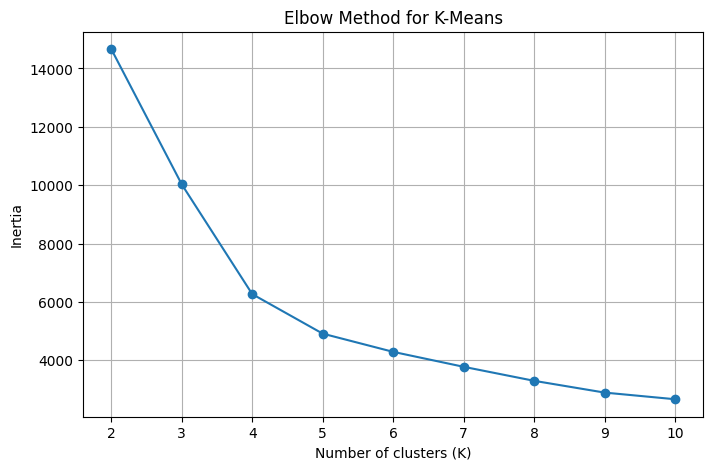

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(list(K_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(K_values))
plt.grid(True)
plt.show()


### 6B. Silhouette Score graph
A higher silhouette score indicates better-defined clusters. Use this together with the elbow graph rather than relying on only one metric.

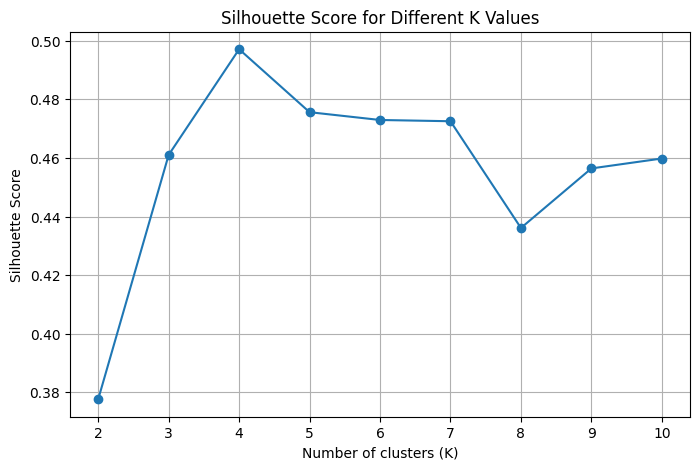

K with the highest Silhouette Score: 4
Highest Silhouette Score: 0.4971


In [8]:
plt.figure(figsize=(8, 5))
plt.plot(list(K_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(K_values))
plt.grid(True)
plt.show()

best_k = list(K_values)[int(np.argmax(silhouette_scores))]
print("K with the highest Silhouette Score:", best_k)
print("Highest Silhouette Score:", round(max(silhouette_scores), 4))


## 7. Train the final K-Means model

For this notebook, we select the K value with the highest Silhouette Score. Compare this choice with the elbow graph too. In a real project, the final K should also make practical sense for the problem.


In [9]:
final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = final_model.fit_predict(X_scaled)

# Add the cluster number to a copy of the original records.
clustered_df = df.copy()
clustered_df["Cluster"] = cluster_labels

print("Final model trained successfully!")
print("Number of clusters:", best_k)
print("\nNumber of records in each cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().to_frame("Number of crashes"))


Final model trained successfully!
Number of clusters: 4

Number of records in each cluster:


,Number of crashes
Cluster,
0,2081
1,776
2,107
3,2304


## 8. Understand the clusters
The table below shows average values of the original features in each cluster. Use it to describe how the groups differ.

In [10]:
cluster_summary = feature_df.copy()
cluster_summary["Cluster"] = cluster_labels
summary_table = cluster_summary.groupby("Cluster").mean().round(2)
display(summary_table)


,Aboard,Fatalities,Ground,Fatality_Rate
Cluster,,,,
0,45.10,41.63,0.04,0.94
1,44.42,4.66,0.11,0.20
2,36.90,32.76,76.87,0.85
3,5.45,5.13,0.02,0.95


## 9. Compare aboard and fatalities by cluster
This scatter plot provides another simple view of the cluster assignments. The axes use a logarithmic scale because the crash counts vary widely.

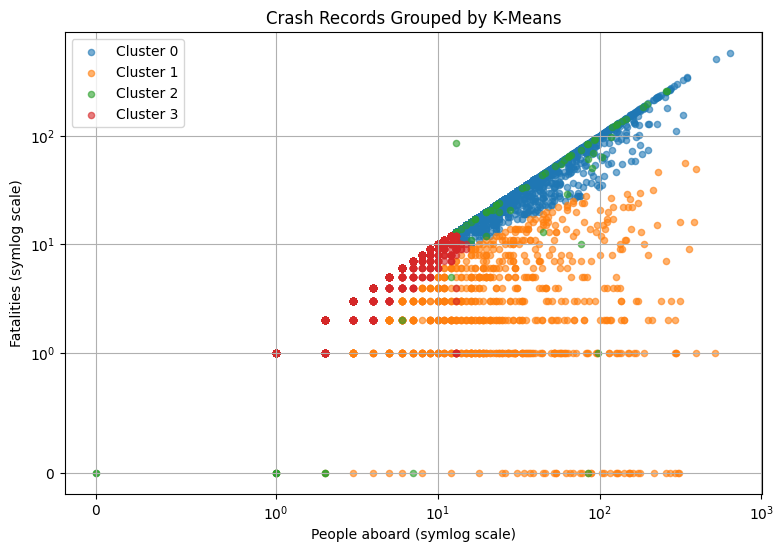

In [12]:
plot_data = feature_df.copy()
plot_data["Cluster"] = cluster_labels

plt.figure(figsize=(9, 6))
for cluster_id in sorted(plot_data["Cluster"].unique()):
    subset = plot_data[plot_data["Cluster"] == cluster_id]
    plt.scatter(
        subset["Aboard"],
        subset["Fatalities"],
        label=f"Cluster {cluster_id}",
        alpha=0.6,
        s=20
    )
plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)
plt.xlabel("People aboard (symlog scale)")
plt.ylabel("Fatalities (symlog scale)")
plt.title("Crash Records Grouped by K-Means")
plt.legend()
plt.grid(True)
plt.show()


## 10. Final observations and conclusion
Review the graphs and cluster summary, then use the following output as a starting point for your lab conclusion.

In [13]:
print(f"The Silhouette Score selected K = {best_k} from the tested values 2 to 10.")
print(f"The corresponding Silhouette Score is {max(silhouette_scores):.4f}.")
print("\nCluster-wise average values:")
display(summary_table)

print("\nConclusion:")
print(
    "K-Means grouped the airplane crash records into clusters based on the number of people aboard, "
    "fatalities, ground fatalities, and fatality rate. The Elbow Method helped compare cluster compactness, "
    "while the Silhouette Score helped compare cluster separation. The PCA and feature-summary outputs "
    "can be used to describe the patterns observed in each cluster. These groups are exploratory and "
    "should not be interpreted as causes or risk predictions."
)


The Silhouette Score selected K = 4 from the tested values 2 to 10.
The corresponding Silhouette Score is 0.4971.

Cluster-wise average values:


,Aboard,Fatalities,Ground,Fatality_Rate
Cluster,,,,
0,45.10,41.63,0.04,0.94
1,44.42,4.66,0.11,0.20
2,36.90,32.76,76.87,0.85
3,5.45,5.13,0.02,0.95



Conclusion:
K-Means grouped the airplane crash records into clusters based on the number of people aboard, fatalities, ground fatalities, and fatality rate. The Elbow Method helped compare cluster compactness, while the Silhouette Score helped compare cluster separation. The PCA and feature-summary outputs can be used to describe the patterns observed in each cluster. These groups are exploratory and should not be interpreted as causes or risk predictions.
